# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

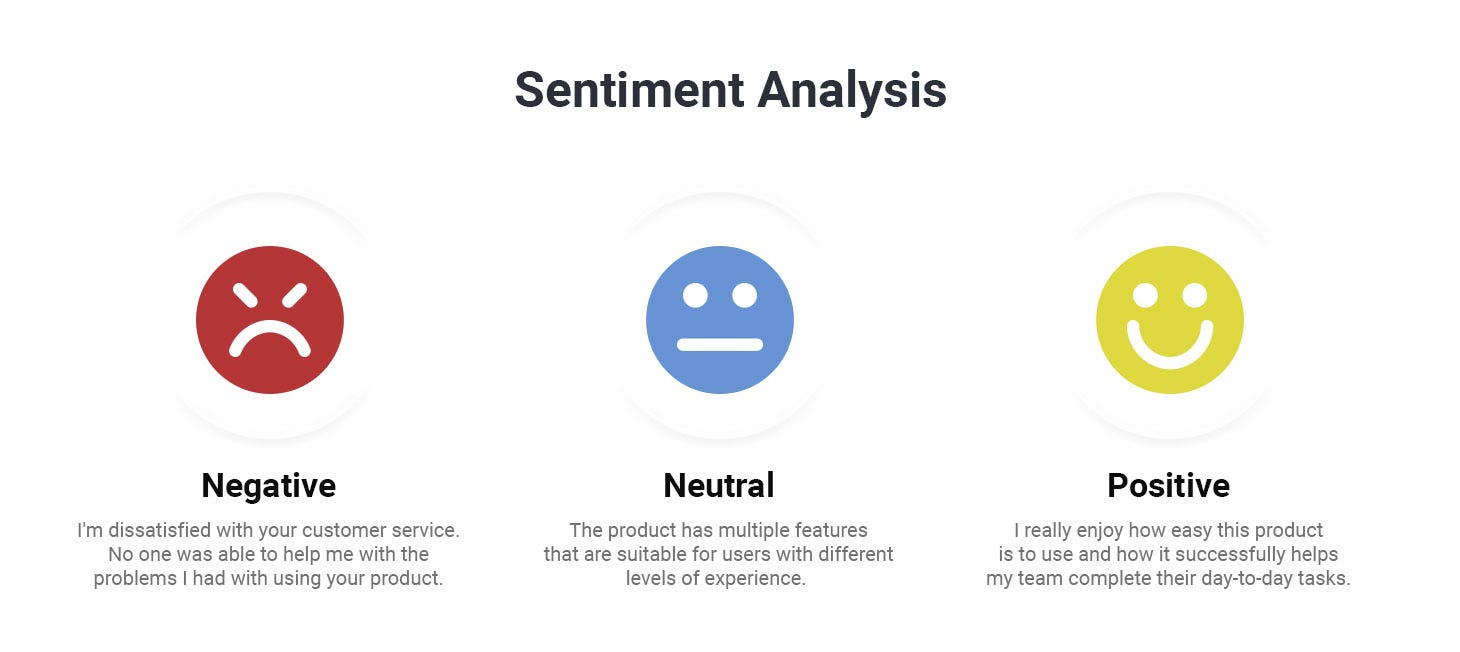

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
# Load the dataset
import pandas as pd

data = pd.read_csv('DisneylandReviews.csv', encoding='latin-1')
data

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
!pip install -U scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\kilwa\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [7]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [8]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [9]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.58       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.98      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

In [10]:
# downloading the dataset
import kagglehub

# Download latest version
path = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones", output_dir="./Dataset")

print("Path to dataset files:", path)

100%|██████████| 32.6M/32.6M [00:02<00:00, 16.4MB/s]

Extracting files...


Path to dataset files: ./Dataset


## Task 1: Load the data and do 5 preprocessing steps

In [11]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Load the dataset
phones = pd.read_csv('Amazon_Unlocked_Mobile.csv')
print(phones.shape)
phones.head()

(413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [12]:
# Inspect missing values and the rating distribution
print(phones.isna().sum())
print()
print(phones['Rating'].value_counts().sort_index())

Product Name        0
Brand Name      65171
Price            5933
Rating              0
Reviews            70
Review Votes    12296
dtype: int64

Rating
1     72350
2     24728
3     31765
4     61392
5    223605
Name: count, dtype: int64


In [ ]:

phones = phones[['Reviews', 'Rating']].copy()

before = len(phones)
phones = phones.dropna(subset=['Reviews', 'Rating'])
phones = phones.drop_duplicates(subset=['Reviews'])
print(f"Step 1: removed {before - len(phones)} rows (missing or duplicate), {len(phones)} remain")


def rating_to_sentiment(rating):
    if rating > 3:
        return 'positive'
    elif rating < 3:
        return 'negative'
    return 'neutral'

phones['Sentiment'] = phones['Rating'].apply(rating_to_sentiment)
print(phones['Sentiment'].value_counts())

Step 1: removed 251350 rows (missing or duplicate), 162490 remain
Sentiment
positive    103773
negative     44351
neutral      14366
Name: count, dtype: int64


In [ ]:

negations = {'not', 'no', 'nor', 'never', 'cannot', 'none', 'nothing', 'neither', 'nobody', 'nowhere'}
stop_words = set(ENGLISH_STOP_WORDS) - negations

def preprocess_text(text):
    text = str(text)

    
    text = text.lower()

    
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 1]

    return ' '.join(tokens)

phones['Clean_Review'] = phones['Reviews'].apply(preprocess_text)


phones = phones[phones['Clean_Review'].str.len() > 0].reset_index(drop=True)

phones[['Reviews', 'Clean_Review', 'Sentiment']].head()

,Reviews,Clean_Review,Sentiment
0,I feel so LUCKY to have found this used (phone...,feel lucky used phone not used hard phone line...,positive
1,"nice phone, nice up grade from my pantach revu...",nice phone nice grade pantach revue clean set ...,positive
2,Very pleased,pleased,positive
3,It works good but it goes slow sometimes but i...,works good goes slow good phone love,positive
4,Great phone to replace my lost phone. The only...,great phone replace lost phone thing volume bu...,positive


## Task 2: Train / test split

In [16]:
from sklearn.model_selection import train_test_split

X = phones['Clean_Review']
y = phones['Sentiment']

train_data, test_data, train_labels, test_labels = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"train_data size: {train_data.shape}")
print(f"test_data size:  {test_data.shape}")
print()
print("Train class distribution:")
print(train_labels.value_counts(normalize=True).round(3))
print()
print("Test class distribution:")
print(test_labels.value_counts(normalize=True).round(3))

train_data size: (129806,)
test_data size:  (32452,)

Train class distribution:
Sentiment
positive    0.638
negative    0.273
neutral     0.088
Name: proportion, dtype: float64

Test class distribution:
Sentiment
positive    0.638
negative    0.273
neutral     0.088
Name: proportion, dtype: float64


## Task 3: Feature extraction with TF-IDF

The vectorizer is **fitted on the training set only** and then used to transform the test set, so no information from the test data leaks into the vocabulary or IDF weights.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,   
    ngram_range=(1, 2),  
    min_df=5             
)

train_vectors = tfidf_vectorizer.fit_transform(train_data)  
test_vectors = tfidf_vectorizer.transform(test_data)        

print(f"Train matrix shape: {train_vectors.shape}")
print(f"Test matrix shape:  {test_vectors.shape}")

Train matrix shape: (129806, 5000)
Test matrix shape:  (32452, 5000)


## Task 4: Train a Naive Bayes classifier

In [18]:
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB()
nb_classifier.fit(train_vectors, train_labels)
print("Model trained.")

Model trained.


## Task 5: Evaluate the model on the test set

In [19]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

predictions = nb_classifier.predict(test_vectors)

accuracy = accuracy_score(test_labels, predictions)
macro_f1 = f1_score(test_labels, predictions, average='macro', zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print()
print("Classification Report:")
print(classification_report(test_labels, predictions, zero_division=0))

Accuracy: 0.8293
Macro F1: 0.5851

Classification Report:
              precision    recall  f1-score   support

    negative       0.78      0.80      0.79      8865
     neutral       0.33      0.04      0.06      2870
    positive       0.85      0.95      0.90     20717

    accuracy                           0.83     32452
   macro avg       0.66      0.60      0.59     32452
weighted avg       0.79      0.83      0.80     32452



## Task 6: Confusion matrix

Confusion Matrix (rows = actual, columns = predicted):
                 pred_negative  pred_neutral  pred_positive
actual_negative           7069            93           1703
actual_neutral            1081           102           1687
actual_positive            865           110          19742


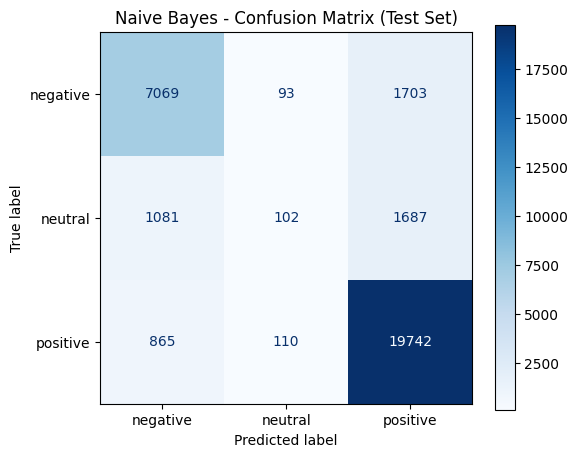

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(test_labels, predictions, labels=labels)


print("Confusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm,
                   index=[f"actual_{l}" for l in labels],
                   columns=[f"pred_{l}" for l in labels]))


fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, cmap='Blues', values_format='d')
ax.set_title('Naive Bayes - Confusion Matrix (Test Set)')
plt.show()